In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

100%|██████████| 170M/170M [48:19<00:00, 58.8kB/s]


In [4]:
# 2. Define Network Parameters

Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
H = 100             # Number of hidden neurons
K = 10              # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)

w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 1e-2
lr_decay = 0.9
reg = 0
loss_history = []

In [5]:
# 3. Training Loop

for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        z1 = x_train.mm(w1) + b1
        h = torch.sigmoid(z1)
        y_pred = h.mm(w2) + b2

        # Loss calculation
        loss = nn.functional.cross_entropy(y_pred, labels)
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = torch.softmax(y_pred, dim=1)
        dy_pred[torch.arange(Ntr), labels] -= 1
        dy_pred /= Ntr

        dw2 = h.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)

        dh = dy_pred.mm(w2.t())
        dz1 = dh * h * (1 - h)

        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        with torch.no_grad():
            w1 -= lr * dw1
            b1 -= lr * db1
            w2 -= lr * dw2
            b2 -= lr * db2

    if t % 1 == 0:
        print(
            f"Epoch {t + 1}/{iterations}, "
            f"Loss: {running_loss / len(trainloader):.4f}"
        )

    # Learning rate decay
    lr *= lr_decay

Epoch 1/10, Loss: 2.3037
Epoch 2/10, Loss: 2.2917
Epoch 3/10, Loss: 2.1537
Epoch 4/10, Loss: 2.0790
Epoch 5/10, Loss: 2.0453
Epoch 6/10, Loss: 2.0058
Epoch 7/10, Loss: 1.9730
Epoch 8/10, Loss: 1.9487
Epoch 9/10, Loss: 1.9311
Epoch 10/10, Loss: 1.9176


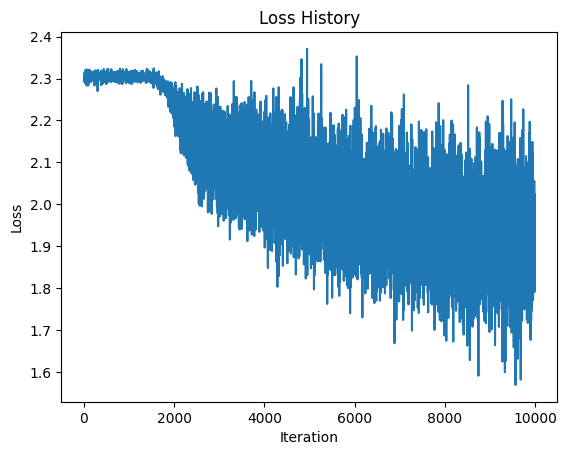

In [6]:
# 4. Plotting the Loss History

plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

In [7]:
# 5. Calculate Accuracy on Training Set

correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        z1 = x_train.mm(w1) + b1
        h = torch.sigmoid(z1)
        y_train_pred = h.mm(w2) + b2

        predicted_train = torch.argmax(y_train_pred, dim=1)

        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train

print(f"Training accuracy: {train_acc:.2f}%")

Training accuracy: 30.55%


In [8]:
# 6. Calculate Accuracy on Test Set

correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        z1 = x_test.mm(w1) + b1
        h = torch.sigmoid(z1)
        y_test_pred = h.mm(w2) + b2

        predicted_test = torch.argmax(y_test_pred, dim=1)

        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test

print(f"Test accuracy: {test_acc:.2f}%")

Test accuracy: 30.90%
